# 02 · Quantize From Scratch

**The showpiece.** Quantization is elementary: find the range of the values, carve it
into a fixed number of buckets (256 for int8, 16 for int4), round each value to the
nearest bucket, and store the integer index plus one scale instead of the float. Here we
build it in a few lines, confirm it matches the library, compute the storage cut exactly,
and run the model with quantized weights to see the outputs barely move.

In [1]:
import sys
from pathlib import Path

_root = Path.cwd()
if not (_root / "src").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import json
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

from src.artifacts import save_figure, save_json
from src.config import load_settings

settings = load_settings()
np.random.seed(settings.seed)
print("settings:", settings.model_dump())

settings: {'seed': 0, 'bit_widths': [8, 4], 'granularity': 'per_channel', 'channel_axis': 1, 'scheme': 'absmax', 'clip_percentile': 99.9, 'clip_sigma': 6.0, 'outlier_sigma': 6.0, 'model_name': 'distilgpt2', 'synthetic': {'rows': 256, 'cols': 256, 'outlier_scale': 10.0, 'n_outliers': 1}}


## Absmax quantization in five lines

Symmetric *absmax* quantization scales by the maximum absolute value so the grid is
centred on zero, then rounds. That is the whole operation:

In [2]:
from src.models.weights import load_model_weights

weights = load_model_weights(settings.model_name)
layer = next(k for k in weights if k.endswith("mlp.c_fc.weight"))
w = weights[layer]

# --- quantize, from scratch ---
qmax = 127                              # int8 signed grid: [-127, 127]
scale = np.abs(w).max() / qmax          # one float: the size of each bucket
codes = np.clip(np.round(w / scale), -qmax, qmax).astype(np.int8)
recon = codes.astype(np.float32) * scale  # dequantize: index * scale
# -------------------------------

print("scale (bucket size):", scale)
print("codes dtype:", codes.dtype, "range:", int(codes.min()), "to", int(codes.max()))
print("first weights :", np.round(w.ravel()[:5], 4))
print("first codes   :", codes.ravel()[:5])
print("first recon   :", np.round(recon.ravel()[:5], 4))

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

scale (bucket size): 0.041376386
codes dtype: int8 range: -57 to 127
first weights : [ 0.1239  0.1034 -0.0096  0.0898 -0.102 ]
first codes   : [ 3  2  0  2 -2]
first recon   : [ 0.1241  0.0828  0.      0.0828 -0.0828]


That matches the library's `quantize_absmax` exactly — the library just adds per-channel
scales, a zero-point scheme, and the bookkeeping. Build it once by hand, trust it forever.

In [3]:
from src.quant.absmax import quantize_absmax
from src.quant.dequant import dequantize

qa = quantize_absmax(w, bits=8, axis=None)
assert np.allclose(recon, dequantize(qa), atol=1e-6)
assert np.array_equal(codes, qa.codes)
print("from-scratch == library:", True)

from-scratch == library: True


## The storage cut is computed, not asserted

int8 stores one byte where fp32 stores four, so the footprint drops to **a quarter**;
int4 to **an eighth**. These numbers come straight from the bit arithmetic.

 bits   bytes   mib  ratio_vs_fp32
   32 9437184 9.000          1.000
    8 2359296 2.250          0.250
    4 1179648 1.125          0.125


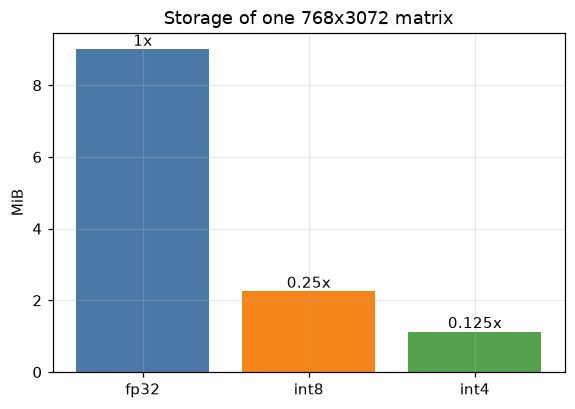

In [4]:
from src.evaluation.size_speed import size_table

table = size_table(w.size, bit_widths=(32, 8, 4))
print(table.to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 4))
colors = ["#4C78A8", "#F58518", "#54A24B"]
ax.bar([f"int{b}" if b < 32 else "fp32" for b in table["bits"]], table["mib"], color=colors)
for x, (mib, ratio) in enumerate(zip(table["mib"], table["ratio_vs_fp32"])):
    ax.text(x, mib, f"{ratio:.3g}x", ha="center", va="bottom")
ax.set_ylabel("MiB")
ax.set_title(f"Storage of one {w.shape[0]}x{w.shape[1]} matrix")
save_figure(fig, "02_size_bars")
plt.show()

## Measure what you lost, and see it

Dequantize and compare. The int8 round-trip error is small and the reconstructed values
track the originals along the identity line. We also compare symmetric *absmax* against
asymmetric *zero-point*, which spends its buckets more efficiently on off-centre ranges.

int8 absmax   : rel error 1.3392%  SNR 37.5 dB


int8 zeropoint: rel error 1.1041%  SNR 39.1 dB
int4 absmax   : rel error 21.9418%  SNR 13.2 dB
int4 zeropoint: rel error 17.9762%  SNR 14.9 dB


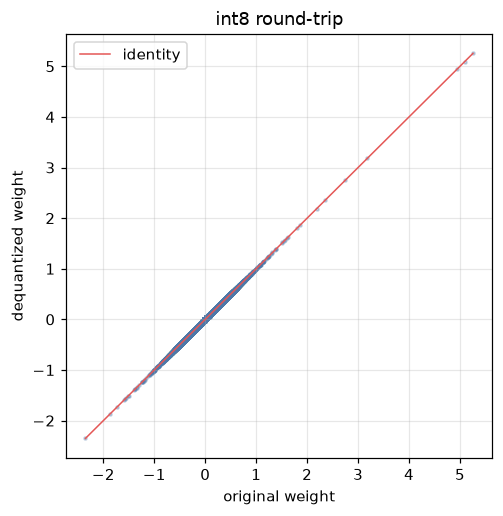

In [5]:
from src.evaluation.reconstruction import reconstruction_error
from src.quant.granularity import quantize
from src.visualisation import plot_quantization_buckets

results = {"layer": layer, "shape": list(w.shape), "scale_example": float(scale)}
results["bytes_fp32"] = int(size_table(w.size, (32,))["bytes"].iloc[0])
results["bytes_int8"] = int(size_table(w.size, (8,))["bytes"].iloc[0])
results["bytes_int4"] = int(size_table(w.size, (4,))["bytes"].iloc[0])

for bits in (8, 4):
    for scheme in ("absmax", "zeropoint"):
        qa_i = quantize(w, bits=bits, scheme=scheme, granularity="per_channel", axis=1)
        err = reconstruction_error(w, dequantize(qa_i))
        results[f"relerr_int{bits}_{scheme}"] = err["rel_fro"]
        print(f"int{bits} {scheme:9s}: rel error {err['rel_fro']:.4%}  SNR {err['snr_db']:.1f} dB")

fig, ax = plt.subplots(figsize=(5, 5))
plot_quantization_buckets(w, quantize(w, bits=8, scheme="absmax", granularity="per_channel", axis=1), ax=ax)
save_figure(fig, "02_buckets_int8")
plt.show()

## Run the model with quantized weights

Reconstruction error is a proxy; the real question is whether the model still behaves.
Quantize **every** 2-D weight of `distilgpt2` to int8 (per-channel), run a forward pass,
and compare the logits. They barely move — the next-token prediction is unchanged.

In [6]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

from src.evaluation.downstream import fake_quantize_2d_weights

tokenizer = AutoTokenizer.from_pretrained(settings.model_name)
model = AutoModelForCausalLM.from_pretrained(settings.model_name).eval()
text = "Quantization lets a large language model run on a"
ids = tokenizer(text, return_tensors="pt")

with torch.no_grad():
    ref_logits = model(**ids).logits

q_model = fake_quantize_2d_weights(model, bits=8, scheme="absmax", granularity="per_channel", axis=1)
with torch.no_grad():
    q_logits = q_model(**ids).logits

cosine = torch.nn.functional.cosine_similarity(ref_logits.flatten(), q_logits.flatten(), dim=0).item()
top1_ref = tokenizer.decode(ref_logits[0, -1].argmax())
top1_int8 = tokenizer.decode(q_logits[0, -1].argmax())
results["downstream_logit_cosine_int8"] = float(cosine)
results["next_token_fp32"] = top1_ref
results["next_token_int8"] = top1_int8

print(f"logit cosine similarity (fp32 vs int8): {cosine:.5f}")
print(f"next token  fp32: '{top1_ref}'   int8: '{top1_int8}'")

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

logit cosine similarity (fp32 vs int8): 0.99993
next token  fp32: ' single'   int8: ' single'


## Takeaway

Quantization is a few lines of rounding arithmetic. int8 cuts the storage to a quarter,
the reconstruction error is a fraction of a percent, and the model's next-token
prediction is unchanged. It really is *nearly free* — on well-behaved weights. Notebook 03
shows the case where it is not.

In [7]:
path = save_json(results, "02_results")
print("saved", path)
results

saved /workspaces/quantization_101/outputs/data/02_results.json


{'layer': 'h.0.mlp.c_fc.weight',
 'shape': [768, 3072],
 'scale_example': 0.04137638583779335,
 'bytes_fp32': 9437184,
 'bytes_int8': 2359296,
 'bytes_int4': 1179648,
 'relerr_int8_absmax': 0.013391613028943539,
 'relerr_int8_zeropoint': 0.011040754616260529,
 'relerr_int4_absmax': 0.21941764652729034,
 'relerr_int4_zeropoint': 0.17976151406764984,
 'downstream_logit_cosine_int8': 0.999928891658783,
 'next_token_fp32': ' single',
 'next_token_int8': ' single'}